In [3]:
# Shared setup for panel-merging figures
from pathlib import Path

import matplotlib.pyplot as plt
import pypdfium2 as pdfium

# Use LaTeX-style serif text for publication-friendly panel labels.
plt.rcParams.update({
    "font.family": "serif",
    "mathtext.fontset": "cm",
})

FIGS_DIR = Path("../results/figs")
LABEL_FONTSIZE = 24
RENDER_SCALE = 2.0


def render_first_page(pdf_path: Path, scale: float = RENDER_SCALE):
    pdf = pdfium.PdfDocument(str(pdf_path))
    page = pdf[0]
    image = page.render(scale=scale).to_pil()
    page.close()
    pdf.close()
    return image


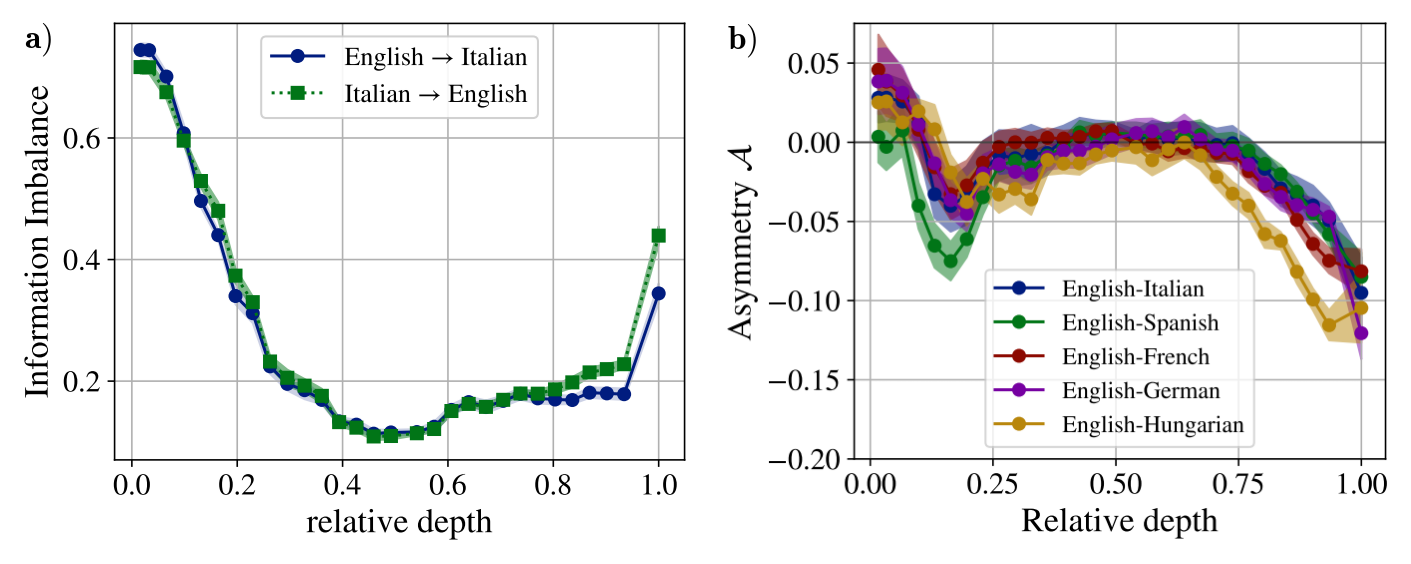

Saved: ../results/figs/English-pivoting-2panel.pdf


In [4]:
# Two-panel variant using original panels b) and c), relabeled as a) and b)

SOURCE_PDFS_2P = [
    FIGS_DIR / "english-pivot-italian-only.pdf",
    FIGS_DIR / "Asymmetry-EN-multi-deepseek.pdf",
]
OUTPUT_PDF_2P = FIGS_DIR / "English-pivoting-2panel.pdf"
PANEL_LABELS_2P = [r"$\mathbf{a)}$", r"$\mathbf{b)}$"]

available_pdfs_2p = [path for path in SOURCE_PDFS_2P if path.exists()]
missing_pdfs_2p = [path for path in SOURCE_PDFS_2P if not path.exists()]

if missing_pdfs_2p:
    print("Missing PDFs (skipped) for 2-panel variant:")
    for path in missing_pdfs_2p:
        print(f"  - {path}")

if not available_pdfs_2p:
    print("No input PDFs found for 2-panel variant.")
else:
    images_2p = [render_first_page(path) for path in available_pdfs_2p]
    fig, axes = plt.subplots(1, len(images_2p), figsize=(7 * len(images_2p), 6), constrained_layout=True)

    if len(images_2p) == 1:
        axes = [axes]

    for i, (ax, image) in enumerate(zip(axes, images_2p)):
        label = PANEL_LABELS_2P[i] if i < len(PANEL_LABELS_2P) else ""
        ax.imshow(image)
        ax.axis("off")
        if label:
            ax.text(
                0.02,
                0.98,
                label,
                transform=ax.transAxes,
                va="top",
                ha="left",
                fontsize=LABEL_FONTSIZE,
                color="black",
                bbox={"facecolor": "white", "edgecolor": "none", "alpha": 0.9, "pad": 2},
                zorder=10,
            )

    fig.savefig(OUTPUT_PDF_2P, bbox_inches="tight")
    plt.show()
    print(f"Saved: {OUTPUT_PDF_2P}")


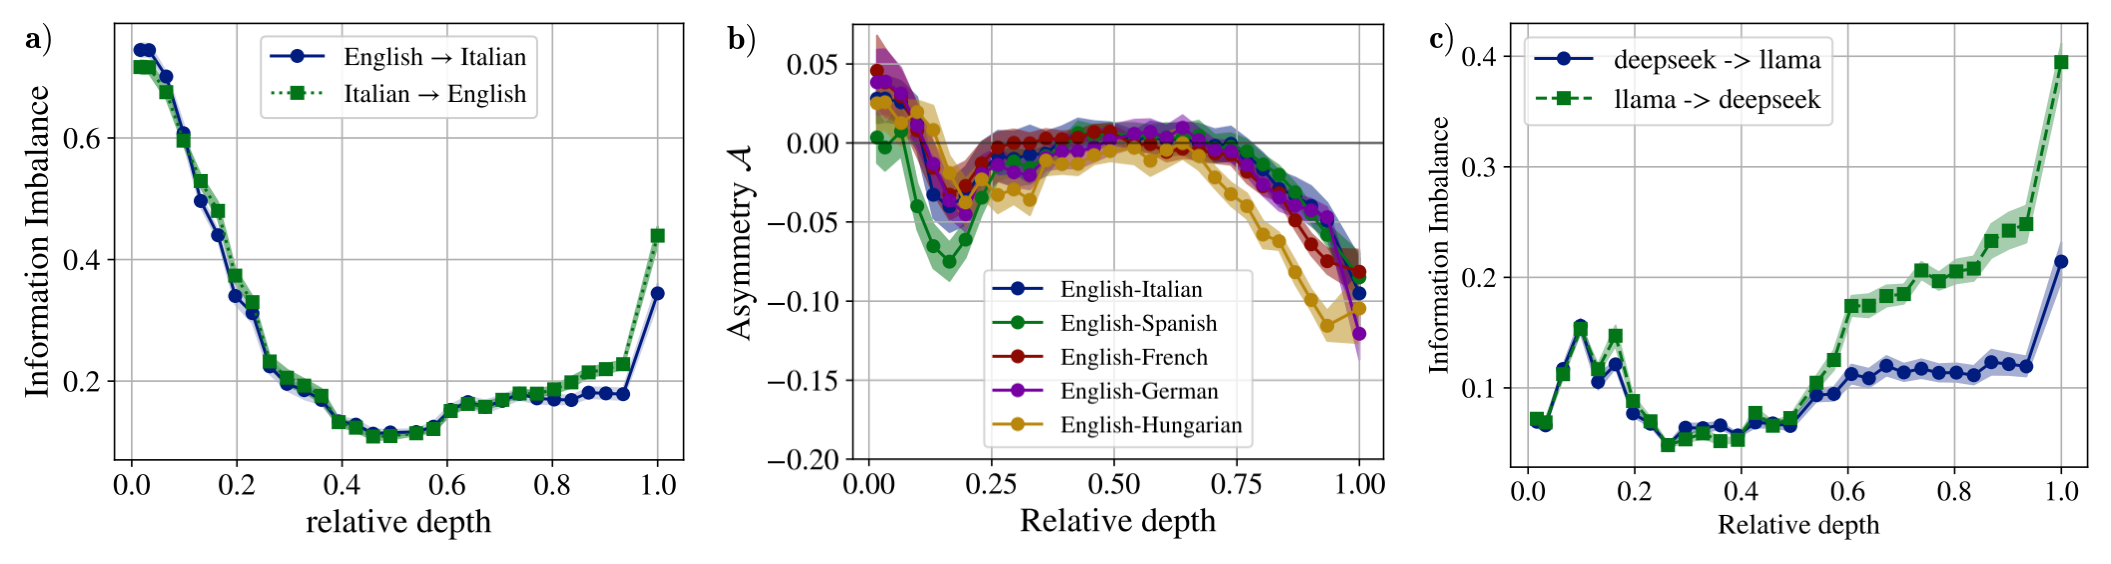

Saved: ../results/figs/English-pivoting-3panel.pdf


In [5]:
# Three-panel variant: keep original 2-panel (a,b) and add ds_vs_llama as panel (c)

SOURCE_PDFS_3P = [
    FIGS_DIR / "english-pivot-italian-only.pdf",
    FIGS_DIR / "Asymmetry-EN-multi-deepseek.pdf",
    Path("/home/laios/deepseek-hidden-states/SA/results/figs/ds_vs_llama_english.pdf"),
]
OUTPUT_PDF_3P = FIGS_DIR / "English-pivoting-3panel.pdf"
PANEL_LABELS_3P = [r"$\mathbf{a)}$", r"$\mathbf{b)}$", r"$\mathbf{c)}$"]

available_pdfs_3p = [path for path in SOURCE_PDFS_3P if path.exists()]
missing_pdfs_3p = [path for path in SOURCE_PDFS_3P if not path.exists()]

if missing_pdfs_3p:
    print("Missing PDFs (skipped) for 3-panel variant:")
    for path in missing_pdfs_3p:
        print(f"  - {path}")

if not available_pdfs_3p:
    print("No input PDFs found for 3-panel variant.")
else:
    images_3p = [render_first_page(path) for path in available_pdfs_3p]
    fig, axes = plt.subplots(1, len(images_3p), figsize=(7 * len(images_3p), 6), constrained_layout=True)

    if len(images_3p) == 1:
        axes = [axes]

    for i, (ax, image) in enumerate(zip(axes, images_3p)):
        label = PANEL_LABELS_3P[i] if i < len(PANEL_LABELS_3P) else ""
        ax.imshow(image)
        ax.axis("off")
        if label:
            ax.text(
                0.02,
                0.98,
                label,
                transform=ax.transAxes,
                va="top",
                ha="left",
                fontsize=LABEL_FONTSIZE,
                color="black",
                bbox={"facecolor": "white", "edgecolor": "none", "alpha": 0.9, "pad": 2},
                zorder=10,
            )

    fig.savefig(OUTPUT_PDF_3P, bbox_inches="tight")
    plt.show()
    print(f"Saved: {OUTPUT_PDF_3P}")
